# AI/ Data Science/ Machine Learning
- Artificial Intelligence (AI): AI refers to the simulation of human intelligence in machines that are designed to think and act like humans. Some examples of AI applications are personal assistants such as Siri and Alexa, autonomous vehicles, and image recognition software.

- Data Science: Data science is the field of study that uses scientific methods, processes, algorithms, and systems to extract knowledge and insights from data in various forms, both structured and unstructured. Examples of data science applications include recommendation systems used by streaming services and fraud detection in financial transactions.

- Machine Learning (ML): Machine learning is a subset of AI that involves the development of algorithms that can learn from and make predictions or decisions without being explicitly programmed to perform the task. Some examples of machine learning applications include spam filters, self-driving cars, and predictive maintenance in manufacturing.


# End Goal
- The end goal of  a datascience project is a presentation containing insights how to drive the business by making new policies which are beneficial and can improve the working of an organization.
- The end goal of a machine learning project is a product which can be utilized to make predictions like health diagnosis, fraud detection, spam filters and etc.


# Machine Learning Types
- There are three types of machine learning supervised, unsupervised and reinforcement learning.
- Supervised learning: In this type of learning, the machine is trained on a labeled dataset, where the desired outcome is already known. The machine uses this training data to make predictions about new, unseen data. For example, email filters that classify emails as spam or not-spam are examples of supervised learning.

- Unsupervised learning: This type of learning involves training the machine on an unlabeled dataset, where the desired outcome is unknown. The machine then finds patterns and relationships in the data on its own. For example, clustering customer data based on their purchasing habits is an example of unsupervised learning.

- Reinforcement learning: In this type of learning, the machine is trained through trial and error, with the goal of maximizing a reward signal. This type of learning is used in control systems and gaming AI, where the machine takes actions in an environment and receives feedback in the form of rewards or penalties.

- Some common real-world applications of machine learning include:
- Image and speech recognition
- Fraud detection
- Recommender systems (e.g. product recommendations on e-commerce websites)
- Predictive maintenance in manufacturing
- Healthcare (e.g. predicting diseases and patient outcomes)



# Supervised Machine Learning
- Supervised Machine Learning are of two types Classification in which we classify classes (e.g classifying defective and non-defective product, classifiying animals into respective categories and etc) and Regression in which we predict continous numerical value (e.g house price prediction, blood pressure prediction, healt cost prediction and etc)

# Classification Example

# Data Source
- The dataset is taken from kaggle, which is a scientific community of data scientists. Where people work and share their projects and experiences.
- [Dataset_link](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)
# Dataset Description
- The dataset is about heart disease. The dataset contains information and variables of patients that developed a heart disease and that didn't.

- The variables included in the dataset are:
- Age: age of the patient (years)
- Sex: sex of the patient (M: Male, F: Female)
- ChestPainType: chest pain type (TA: Typical Angina, - ATA: Atypical Angina, NAP: Non-Anginal Pain, ASY: Asymptomatic
- RestingBP: resting blood pressure (mm Hg)
- Cholesterol: serum cholesterol (mm/dl)
- FastingBS: fasting blood sugar (1: if FastingBS > 120 mg/dl, 0: otherwise)
- RestingECG: resting electrocardiogram results (Normal: Normal, ST: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV), LVH: showing probable or definite left ventricular hypertrophy by Estes' criteria)
- MaxHR: maximum heart rate achieved (Numeric value between 60 and 202)
- ExerciseAngina: exercise-induced angina (Y: Yes, N: No)
- Oldpeak: oldpeak = ST (Numeric value measured in depression)
- ST_Slope: the slope of the peak exercise ST segment (Up: upsloping, Flat: flat, Down: downsloping)
- HeartDisease: output class (1: heart disease, 0: Normal)

# Goal:
- Our goal is to develop a binary classification model which can be used to predict whether the patient will develop heart disease or not. It can be an extremely useful application in the healthcare system, where diseases can be predicted to provide patients with optimum therapy and patient care.

In [ ]:
# importing libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
# importing ml models to use
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn import metrics
from sklearn.ensemble import VotingClassifier
from sklearn.decomposition import PCA
from scipy.stats import ttest_ind
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# loading the dataset
df = pd.read_csv("/content/heart.csv")

In [ ]:
# exploring the data
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
# checking info about the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [ ]:
# getting basic statistics for the data
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


# Data Cleaning

In [ ]:
# checking for null values
df.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

- no null values spotted in the dataset

In [ ]:
# checking for duplicates
df[df.duplicated()]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease


In [ ]:
# getting numerical columns
num_col = [col for col in df.columns if df[col].dtype == "int64" or df[col].dtype == "float64"]

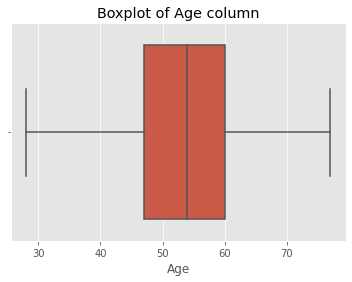

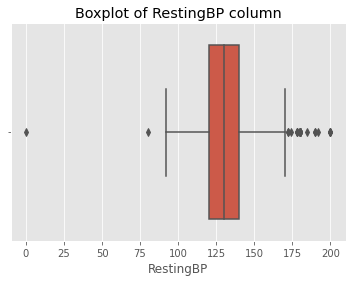

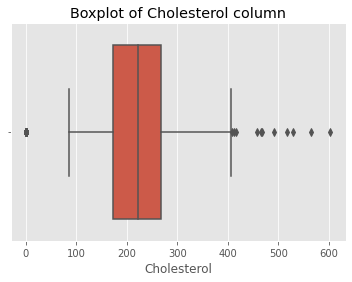

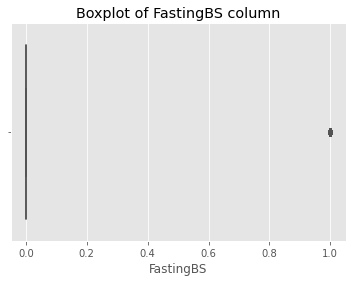

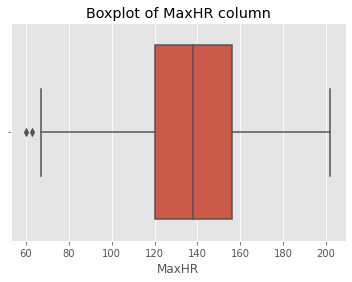

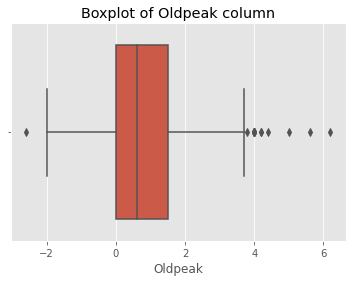

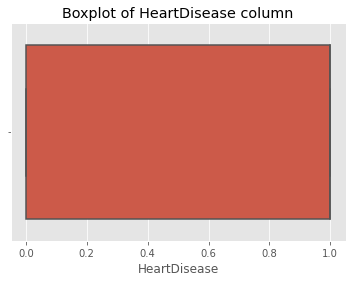

In [ ]:
# making boxplot for numerical columns to detect outliers
plt.style.use("ggplot")
for col in num_col:
    sns.boxplot(x=col,data=df)
    plt.title("Boxplot of {} column".format(col))
    plt.show()

- The boxplot of restingBP, Cholesterol, Max HR and Old peak contain outliers. I will use IQR method to remove these outliers

In [ ]:
# storing columns with outliers in a list
outlier_col = ['RestingBP', 'Cholesterol','MaxHR','Oldpeak']

In [ ]:
# removing outliers from the columns in which outliers
for col_name in outlier_col:
    q1 = df[col_name].quantile(0.25)
    q3 = df[col_name].quantile(0.75)
    iqr = q3-q1 #Interquartile range
    fence_low  = q1-1.5*iqr
    fence_high = q3+1.5*iqr
    df_out = df.loc[(df[col_name] > fence_low) & (df[col_name] < fence_high)]


In [ ]:
# Blood pressure and Cholesterol cannot be zero so taking values greater than zero
df_out = df_out.loc[df["RestingBP"] > 0]
df_out = df_out.loc[df["Cholesterol"] > 0]

In [ ]:
print("Shape of original dataframe {}".format(df.shape))
print("Shape of cleaned dataframe {}".format(df_out.shape))

Shape of original dataframe (918, 12)
Shape of cleaned dataframe (731, 12)


# Data Analysis

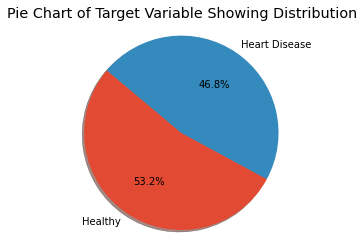

In [ ]:
# making pie chart
labels=["Healthy","Heart Disease"]

healthy_or_not = df_out['HeartDisease'].value_counts().tolist()
values = [healthy_or_not[0], healthy_or_not[1]]
plt.pie(values, labels=labels,
        autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title("Pie Chart of Target Variable Showing Distribution")
plt.show()



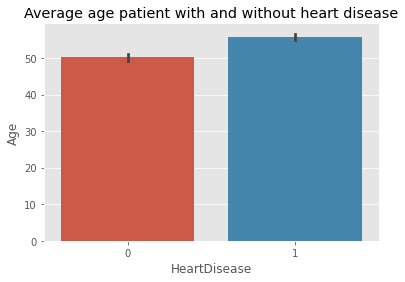

In [ ]:
# average age of people getting heart disease and those who do not
sns.barplot(x="HeartDisease",y="Age",data=df_out)
plt.title("Average age patient with and without heart disease")
plt.show()

- There seem to be a difference in ages of patients with and without heart disease. We can check if this difference is statistically significant or not by applying a t-test.

# T-test
- A t test is a statistical test that is used to compare the means of two groups. This test tells whether the two groups are different or not.

- Null Hypothesis: There is no difference in the age of patient with and without heart disease.

- Alternative Hypothesis: There is difference in the age of patient with and without heart disease.

- significance level or alpha level use is 5% or 0.05.

In [ ]:
# applying t-test to determine if significance difference in means of patient with disease and without disease
age_with_disease = df_out[df_out["HeartDisease"] == 1]["Age"]
age_without_disease = df_out[df_out["HeartDisease"] == 0]["Age"]

stat,p = ttest_ind(age_with_disease,age_without_disease)
if p > 0.05:
    print("The p-value is greater than 0.05, so we cannot reject the null hypothesis. There is no difference in the age of patient with and without heart disease.")
else:
    print("The p-value is less than 0.05, so we can reject the null hypothesis. There is difference in the age of patient with and without heart disease.")

The p-value is less than 0.05, so we can reject the null hypothesis. There is difference in the age of patient with and without heart disease.


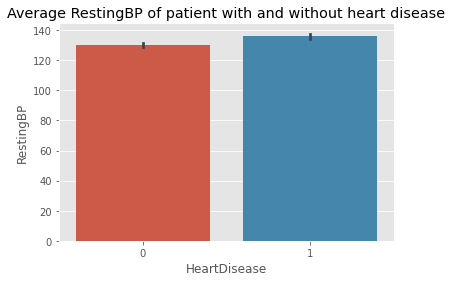

In [ ]:
# average resting blood pressure of people getting heart disease and those who do not
sns.barplot(x="HeartDisease",y="RestingBP",data=df_out)
plt.title("Average RestingBP of patient with and without heart disease")
plt.show()

- There seem to be but not much difference in the average resting blood pressure of patient with and without disease

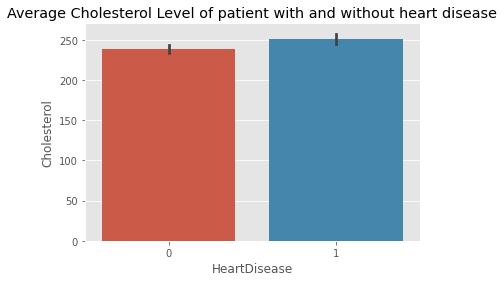

In [ ]:
# average resting blood pressur of people getting heart disease and those who do not
sns.barplot(x="HeartDisease",y="Cholesterol",data=df_out)
plt.title("Average Cholesterol Level of patient with and without heart disease")
plt.show()

- The above barplot shows a big difference in the average cholesterol level of patient with and without heart disease

# T-test
- A t test is a statistical test that is used to compare the means of two groups. This test tells whether the two groups are different or not.

- Null Hypothesis: There is no difference in the cholesterol level of patient with and without heart disease.

- Alternative Hypothesis: There is difference in the cholesterol level of patient with and without heart disease.

- significance level or alpha level use is 5% or 0.05.

In [ ]:
# applying t-test to determine if the cholesterol level in patient with and without disease is differenct
cholesterol_with_disease = df_out[df_out["HeartDisease"] == 1]["Cholesterol"]
cholesterol_without_disease = df_out[df_out["HeartDisease"] == 0]["Cholesterol"]

stat,p = ttest_ind(cholesterol_with_disease,cholesterol_without_disease)
if p > 0.05:
    print("The p-value is greater than 0.05, so we cannot reject the null hypothesis. There is no difference in the Cholesterol Level of patient with and without heart disease.")
else:
    print("The p-value is less than 0.05, so we can reject the null hypothesis. There is difference in the Cholesterol Level of patient with and without heart disease.")

The p-value is less than 0.05, so we can reject the null hypothesis. There is difference in the Cholesterol Level of patient with and without heart disease.


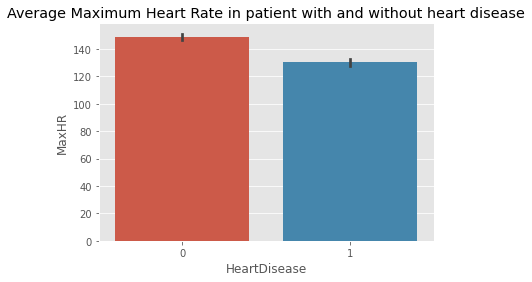

In [ ]:
# average resting blood pressur of people getting heart disease and those who do not
sns.barplot(x="HeartDisease",y="MaxHR",data=df_out)
plt.title("Average Maximum Heart Rate in patient with and without heart disease")
plt.show()

- There seem to be a lower average heart rate of patient with heart disease as compared to those who didn't have heart disease

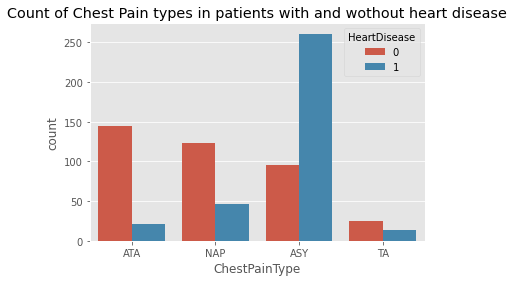

In [ ]:
# making countplot of chestpaintype and checking frequency distribution with context of patient with and without heart disease
sns.countplot(x="ChestPainType",data=df_out,hue="HeartDisease")
plt.title("Count of Chest Pain types in patients with and wothout heart disease")
plt.show()

- The countplot shows that the most common type of pain in people with heart disease is "Asymptomatic".

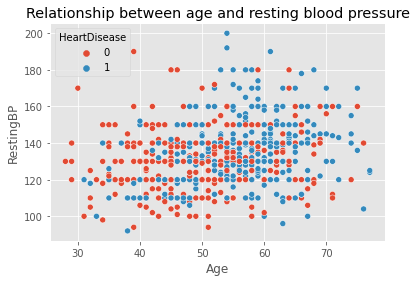

In [ ]:
# making a scatterplot to determine relationship between age and resting blood pressure
sns.scatterplot(x="Age",y="RestingBP",data=df_out,hue="HeartDisease")
plt.title("Relationship between age and resting blood pressure")
plt.show()

- There seem to be but not very strong correlation between age and resting blood pressure, we can compute pearson correlation to check the strenght of correlation

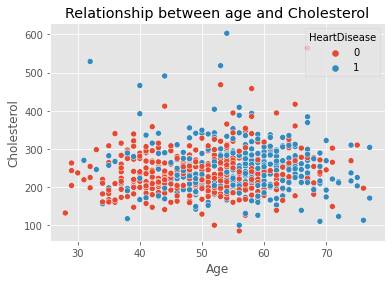

In [ ]:
# making a scatterplot to determine relationship between age and Cholesterol Level
sns.scatterplot(x="Age",y="Cholesterol",data=df_out,hue="HeartDisease")
plt.title("Relationship between age and Cholesterol")
plt.show()

- There seem to be but not very strong correlation between age and cholesterol, we can compute pearson correlation to check the strenght of correlation

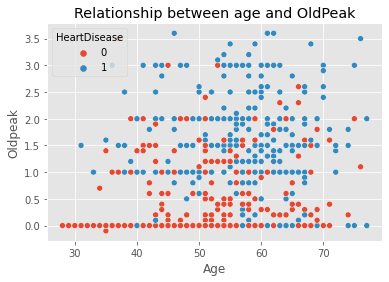

In [ ]:
# making a scatterplot to determine relationship between age and Old Peak
sns.scatterplot(x="Age",y="Oldpeak",data=df_out,hue="HeartDisease")
plt.title("Relationship between age and OldPeak")
plt.show()

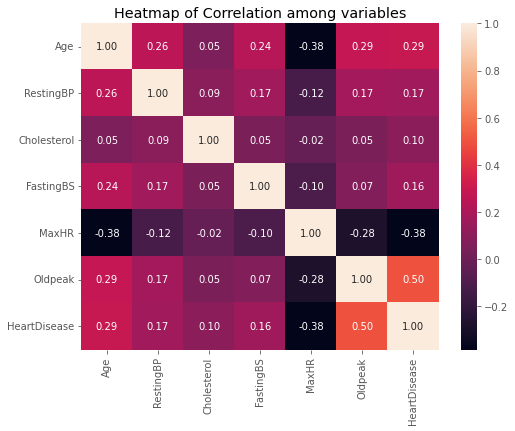

In [ ]:
# computing pearson correlation and visualizaing it using heatmap
corr = df_out.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr,fmt=".2f",annot=True)
plt.title("Heatmap of Correlation among variables")
plt.show()

- A correlation coefficient is a number between -1 and 1 that tells you the strength and direction of a relationship between variables. If correlation of two variables is +1 than they are strongly correlated and have the same direction which means if one is increased the other one also tends to increase and vice verse

# Data Preparation For Machine Learning

In [ ]:
# splitting data into features and target variable
X = df.copy()
X.drop("HeartDisease",axis=1,inplace=True)
y = df[["HeartDisease"]]

In [ ]:
# getting dummies for categorical variables
X_dummy = pd.get_dummies(X)

In [ ]:
# splitting data into training and test set
X_train,X_test,y_train,y_test = train_test_split(X_dummy,y,test_size=0.2,random_state=21)

# Machine Learning

In [ ]:
# ### Applying cross validation of 5 folds with all the models with default parameters
knn = KNeighborsClassifier(n_neighbors=2)
dtc = DecisionTreeClassifier()
rfc = RandomForestClassifier()
lgc = LogisticRegression()
svc = SVC()
nbc = GaussianNB()
abc = AdaBoostClassifier()
gbc = GradientBoostingClassifier()
sgc = SGDClassifier()
models = [knn,dtc,rfc,lgc,svc,nbc,abc,gbc,sgc]
model_names = ["KNearestNeighbor","Decision Tree","Random Forest","Logistic Regression","Support Vector","Naive Bayes","Ada Boost","Gradient Boosting","Stochastic Gradient"]
mean_score = []

for model,name in zip(models,model_names):
    cross_score = cross_val_score(model,X_train,y_train,cv=5)
    print("Cross validation scores for {} model is {}".format(name,cross_score))
    average_score = np.mean(cross_score)
    mean_score.append(average_score)
    print("-" * 100)

Cross validation scores for KNearestNeighbor model is [0.72789116 0.62585034 0.59863946 0.65306122 0.54794521]
----------------------------------------------------------------------------------------------------
Cross validation scores for Decision Tree model is [0.82993197 0.73469388 0.74829932 0.73469388 0.84246575]
----------------------------------------------------------------------------------------------------
Cross validation scores for Random Forest model is [0.9047619  0.87755102 0.82993197 0.81632653 0.8630137 ]
----------------------------------------------------------------------------------------------------
Cross validation scores for Logistic Regression model is [0.89795918 0.89115646 0.83673469 0.80952381 0.88356164]
----------------------------------------------------------------------------------------------------
Cross validation scores for Support Vector model is [0.7414966  0.65986395 0.73469388 0.69387755 0.69863014]
----------------------------------------------

- Cross validation is done to see if the ml models are overfitting and underfitting. In our case models are overfitting as it is evident from the difference in accuracy scores of each fold. We can regularize model by applying constraints.

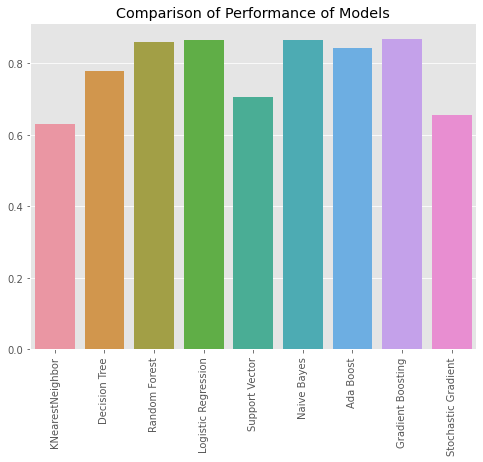

In [ ]:
# plotting bar chart to compare the model performances and pointing out the best one
plt.figure(figsize=(8,6))
sns.barplot(model_names,mean_score)
plt.title("Comparison of Performance of Models")
plt.xticks(rotation=90)
plt.show()

- The top performing models are Random Forest, Logistic Regression and gradient boosting

# Hyperparameter Tuning of Top Models

In [ ]:
# applying grid search cv to tune for the best parameters
param = {"n_estimators":[150,200,300,350],"max_depth":[2,4,6,8],"criterion":["gini","entropy","logloss"],"max_features":["sqrt","log2","None"],"class_weight":["balanced","balanced_subsample"]}
grid_search_rfc = GridSearchCV(rfc,param_grid=param,cv=5)

In [ ]:
# fitting random forest grid on training set
grid_search_rfc.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(),
             param_grid={'class_weight': ['balanced', 'balanced_subsample'],
                         'criterion': ['gini', 'entropy', 'logloss'],
                         'max_depth': [2, 4, 6, 8],
                         'max_features': ['sqrt', 'log2', 'None'],
                         'n_estimators': [150, 200, 300, 350]})

In [ ]:
print("Tuned Random Forest Parameters: {}".format(grid_search_rfc.best_params_))
print("Best score is {}".format(grid_search_rfc.best_score_))

Tuned Random Forest Parameters: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'max_features': 'log2', 'n_estimators': 300}
Best score is 0.8692200167738328


In [ ]:
# taking prediction on testing data using the best parameters given by grid search of RFC
y_pred_rfc = grid_search_rfc.best_estimator_.predict(X_test)

# computing accuracy score
accuracy_rfc_test = metrics.accuracy_score(y_test,y_pred_rfc)

print("Accuracy Score of RFC on testing data {}".format(accuracy_rfc_test))

Accuracy Score of RFC on testing data 0.8804347826086957


In [ ]:
# Performing grid search of Logistic Regresssion model to find the best hyperparameters
log_reg = LogisticRegression()
log_param = {"penalty":['l1', 'l2', 'elasticnet', 'none'],"C":[0.8,1.0,1.2,1.4],"solver":['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga'],"max_iter":[100,150,200],"multi_class":["ovr"]}
grid_search_log_reg = GridSearchCV(log_reg,param_grid=log_param,cv=5)
grid_search_log_reg.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(),
             param_grid={'C': [0.8, 1.0, 1.2, 1.4], 'max_iter': [100, 150, 200],
                         'multi_class': ['ovr'],
                         'penalty': ['l1', 'l2', 'elasticnet', 'none'],
                         'solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag',
                                    'saga']})

In [ ]:
print("Tuned Logistic Regression Parameters: {}".format(grid_search_log_reg.best_params_))
print("Best score is {}".format(grid_search_log_reg.best_score_))

Tuned Logistic Regression Parameters: {'C': 0.8, 'max_iter': 100, 'multi_class': 'ovr', 'penalty': 'l2', 'solver': 'liblinear'}
Best score is 0.863787158699096


In [ ]:
# taking prediction on testing data using the best parameters given by grid search of logistic regression
y_pred_logreg = grid_search_log_reg.best_estimator_.predict(X_test)

# computing accuracy score
accuracy_logreg_test = metrics.accuracy_score(y_test,y_pred_logreg)

print("Accuracy Score of Logreg on testing data {}".format(accuracy_logreg_test))

Accuracy Score of Logreg on testing data 0.8641304347826086


In [ ]:
# Performing grid search of Gradient Boosting model to find the best hyperparameters
parameters = {
    "loss":["deviance"],
    "learning_rate": [0.05, 0.1, 0.15,],
    "max_depth":[3,5,8],
    "max_features":["log2","sqrt"],
    "criterion": ["friedman_mse",  "mae"],
    "n_estimators":[10,50,100]
    }
clf = GridSearchCV(GradientBoostingClassifier(), parameters,refit=False,cv=2, n_jobs=-1)

clf.fit(X_train, y_train)

GridSearchCV(cv=2, estimator=GradientBoostingClassifier(), n_jobs=-1,
             param_grid={'criterion': ['friedman_mse', 'mae'],
                         'learning_rate': [0.05, 0.1, 0.15],
                         'loss': ['deviance'], 'max_depth': [3, 5, 8],
                         'max_features': ['log2', 'sqrt'],
                         'n_estimators': [10, 50, 100]},
             refit=False)

In [ ]:
print("Tuned Gradient Boosting Parameters: {}".format(clf.best_params_))
print("Best score is {}".format(clf.best_score_))

Tuned Gradient Boosting Parameters: {'criterion': 'mae', 'learning_rate': 0.15, 'loss': 'deviance', 'max_depth': 3, 'max_features': 'log2', 'n_estimators': 50}
Best score is 0.8664850136239781


In [ ]:
# taking prediction on testing data using the best parameters given by grid search of gradient boosting
y_pred_gb = grid_search_log_reg.best_estimator_.predict(X_test)

# computing accuracy score
accuracy_gb_test = metrics.accuracy_score(y_test,y_pred_gb)

print("Accuracy Score of Gradient Boosting on testing data {}".format(accuracy_gb_test))

Accuracy Score of Gradient Boosting on testing data 0.8641304347826086


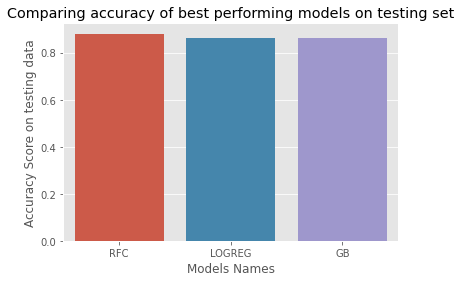

In [ ]:
# storing names of models and their accuracy on testing set
testing_models = ["RFC","LOGREG","GB"]
testing_models_accuracy = [accuracy_rfc_test,accuracy_logreg_test,accuracy_gb_test]

# making a barplot to compare accuracy on testing data of best models
sns.barplot(testing_models,testing_models_accuracy)
plt.xlabel("Models Names")
plt.ylabel("Accuracy Score on testing data")
plt.title("Comparing accuracy of best performing models on testing set")
plt.show()

- All three models nearly performed equal on the testing set

# PCA
- PCA (Principal Component Analysis) is a dimensionality reduction technique that transforms the data into a new coordinate system, where the first axis (principal component) explains the maximum variance in the data, the second axis explains the second maximum variance, and so on. The aim of PCA is to identify the underlying structure in the data by reducing its complexity.

- After performing PCA, the following steps can be taken to analyze the results:

- Scree plot: This is a plot of the explained variance of each principal component. The plot helps to determine the number of principal components to retain, which is usually the number of components that explain a significant amount of variance in the data.

- Loadings plot: This is a plot that displays the contribution of each feature (variable) to each principal component. It helps to understand the relationship between the variables and the principal components.

- Biplot: This is a plot that displays both the observations (data points) and the variables in the new reduced-dimensional space.

In [ ]:
# getting dummies of categorical variables in data frame
df_dummy = pd.get_dummies(df)

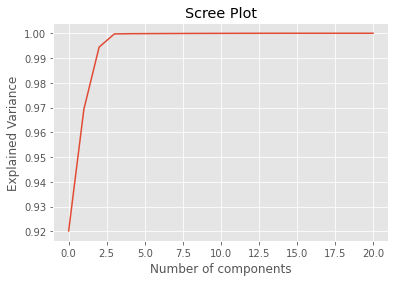

In [ ]:
# Performing PCA
pca = PCA()
pca.fit(df_dummy)

# Scree plot
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.title("Scree Plot")
plt.xlabel('Number of components')
plt.ylabel('Explained Variance')
plt.show()




- The plot suggests that more than 99% of the variance can be explained by using 2 variables

# Regression Example

In [ ]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
plt.style.use("ggplot")
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# loading the data of p1_table and p4_table
p1_table = pd.read_excel('/content/Book1.xlsx', sheet_name='Sheet1')
p4_table = pd.read_excel('/content/Book1.xlsx', sheet_name='Sheet2')

In [ ]:
# printing shape of both tables to identify number of rows and columns in each
print("Shape of p1 table {}".format(p1_table.shape))
print("Shape of p4 table {}".format(p4_table.shape))

Shape of p1 table (56, 25)
Shape of p4 table (56, 25)


In [ ]:
# checking any inconsistancies in column names of both tables before concatenating
p1_table.columns == p4_table.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True])

In [ ]:
# joining both the tables row wise
df = pd.concat([p1_table,p4_table],axis=0)

# checking shape of the resulting dataset to ensure that data is correctly concatenated
df.shape

(112, 25)

### The two tables are correctly concatenated because the number of rows are twice and column numbers are same in the resulting dataset

In [ ]:
# checking the dataset
df.head()

,Area Code,Area Name,Total recorded crime (excluding fraud),Violence\n against\n the person,Homicide,Violence with injury,Violence without injury,Stalking and\n harassment,Death or serious\n injury - unlawful\n driving,Sexual offences,Robbery,Theft offences,Burglary\n [note 3],Residential\n burglary [note 3],Non-residential\n burglary [note 3],Vehicle offences,Theft from the person,Bicycle theft,Shoplifting,Other theft offences,Criminal damage\n and arson,Drug offences,Possession of\n weapons offences,Public order offences,Miscellaneous crimes
0,K04000001,ENGLAND AND WALES [note 4],4856063,1885618,627,494136,716521,673605,729,164763,62803,1358226,265508,195497,70011,344487,59421,79160,247068,362582,502802,198140,45630,524572,113509
1,E92000001,ENGLAND,4573648,1777131,599,467351,677995,630491,695,155727,60966,1295455,254787,187791,66996,333806,55883,74049,234242,342688,466407,183352,43264,483935,107411
2,E12000001,North East,254730,99138,19,24105,33985,40986,43,8450,1424,61172,12200,9085,3115,11075,1231,2568,15922,18176,36859,7336,1961,30812,7578
3,E23000013,Cleveland,65461,25360,7,5579,9339,10420,15,2125,568,16149,3772,2930,842,2750,332,506,4337,4452,9210,2374,590,7131,1954
4,E23000008,Durham,57363,25390,4,5013,8185,12177,11,1873,175,12302,2595,1823,772,2102,195,363,3473,3574,8602,1440,279,5602,1700


In [ ]:
# changing the max columns display function
pd.options.display.max_columns = None

In [ ]:
# computing basic statistics for all the numerical columns
# mean, std, median, min, max and few others
df.describe()

,Total recorded crime (excluding fraud),Violence\n against\n the person,Homicide,Violence with injury,Violence without injury,Stalking and\n harassment,Death or serious\n injury - unlawful\n driving,Sexual offences,Robbery,Theft offences,Burglary\n [note 3],Residential\n burglary [note 3],Non-residential\n burglary [note 3],Vehicle offences,Theft from the person,Bicycle theft,Shoplifting,Other theft offences,Criminal damage\n and arson,Drug offences,Possession of\n weapons offences,Public order offences,Miscellaneous crimes
count,1.120000e+02,1.120000e+02,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000,1.120000e+02,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000
mean,3.469377e+05,1.276358e+05,46.830357,35433.017857,50262.008929,41838.133929,55.785714,11145.241071,5039.178571,1.080484e+05,21761.062500,15648.794643,6112.267857,27225.946429,5196.660714,5588.187500,19642.446429,28634.071429,35990.035714,13804.383929,3220.080357,34316.535714,7738.116071
std,8.829352e+05,3.235721e+05,120.442419,89922.704059,127665.780622,106648.805500,143.254981,28260.573043,13894.090399,2.808618e+05,56520.453646,40634.512439,15935.778476,71739.554931,14970.408755,14616.224145,50134.286287,74153.508490,90905.342846,35724.436989,8227.293775,86987.274402,19620.645614
min,4.246000e+03,5.890000e+02,0.000000,147.000000,356.000000,86.000000,0.000000,52.000000,52.000000,2.074000e+03,1.000000,1.000000,0.000000,127.000000,79.000000,120.000000,594.000000,468.000000,203.000000,687.000000,46.000000,321.000000,189.000000
25%,5.910550e+04,2.361875e+04,7.000000,5821.750000,9341.250000,7191.750000,7.000000,2094.750000,415.750000,1.602825e+04,3199.250000,2104.000000,1004.750000,3101.750000,337.000000,803.500000,3512.750000,4439.000000,7079.750000,1905.500000,528.250000,5668.750000,1430.250000
50%,9.510350e+04,3.779950e+04,12.500000,11114.500000,13240.000000,13021.000000,17.000000,3316.000000,841.500000,2.909250e+04,5640.000000,4105.500000,1703.000000,6535.500000,747.500000,1412.000000,6609.000000,7659.500000,11442.500000,3460.500000,867.000000,10454.500000,2295.000000
75%,2.564868e+05,9.690675e+04,28.750000,24402.500000,36009.250000,36335.000000,39.250000,8146.500000,1911.750000,6.890025e+04,14088.750000,10333.000000,4283.750000,15324.250000,2326.750000,3367.000000,12616.250000,18178.750000,28572.750000,8368.750000,2032.750000,29957.500000,6425.000000
max,5.030794e+06,1.885618e+06,701.000000,513194.000000,716521.000000,673605.000000,851.000000,164763.000000,79659.000000,1.715070e+06,349775.000000,246782.000000,102993.000000,424530.000000,92670.000000,82411.000000,311431.000000,454253.000000,527027.000000,198140.000000,46120.000000,524572.000000,113509.000000


In [ ]:
# getting info about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 112 entries, 0 to 55
Data columns (total 25 columns):
 #   Column                                        Non-Null Count  Dtype 
---  ------                                        --------------  ----- 
 0   Area Code                                     110 non-null    object
 1   Area Name                                     112 non-null    object
 2   Total recorded crime (excluding fraud)        112 non-null    int64 
 3   Violence
 against
 the person                 112 non-null    int64 
 4   Homicide                                      112 non-null    int64 
 5   Violence with injury                          112 non-null    int64 
 6   Violence without injury                       112 non-null    int64 
 7   Stalking and
 harassment                      112 non-null    int64 
 8   Death or serious
 injury - unlawful
 driving  112 non-null    int64 
 9   Sexual offences                               112 non-null    int64 
 10  Rob

In [ ]:
# checking for null values in the dataframe
df.isna().sum()

Area Code                                         2
Area Name                                         0
Total recorded crime (excluding fraud)            0
Violence\n against\n the person                   0
Homicide                                          0
Violence with injury                              0
Violence without injury                           0
Stalking and\n harassment                         0
Death or serious\n injury - unlawful\n driving    0
Sexual offences                                   0
Robbery                                           0
Theft offences                                    0
Burglary\n [note 3]                               0
Residential\n burglary [note 3]                   0
Non-residential\n burglary [note 3]               0
Vehicle offences                                  0
Theft from the person                             0
Bicycle theft                                     0
Shoplifting                                       0
Other theft 

### Only area code column contains two null values, as we are not going to use area code so I will keep these values and later will drop the column


In [ ]:
# checking for duplicate values in the data frame
df[df.duplicated()]

,Area Code,Area Name,Total recorded crime (excluding fraud),Violence\n against\n the person,Homicide,Violence with injury,Violence without injury,Stalking and\n harassment,Death or serious\n injury - unlawful\n driving,Sexual offences,Robbery,Theft offences,Burglary\n [note 3],Residential\n burglary [note 3],Non-residential\n burglary [note 3],Vehicle offences,Theft from the person,Bicycle theft,Shoplifting,Other theft offences,Criminal damage\n and arson,Drug offences,Possession of\n weapons offences,Public order offences,Miscellaneous crimes


### No duplicate value is spotted in the dataframe

In [ ]:
# isolating numerical columns in a list for smooth operations
num_col = [col for col in df.columns if df[col].dtype=="int64" or df[col].dtype=="float64"]

In [ ]:
 # computing for each column : mean, mode, median, standard deviation, variance,
# making empty list for each metric
mean = []
mode = []
median = []
std = []
variance = []

# applying the for loop that iterates through the numerical columns and compute the metrics and append them back in the lists
for col in num_col:

  # computing mean
  col_mean = df[col].mean()

  # computing mode (some columns have more than one mode due to equal occurence of values so keeping the first mode for those columns)
  col_mode = df[col].mode()[0]

  # computing median
  col_median = df[col].median()

  # computing standard deviation
  col_std = df[col].std()

  # computing variance
  col_var = df[col].var()

  # appeding mean computed to the mean list
  mean.append(col_mean)

  # appeding mode computed to the mode list
  mode.append(col_mode)

  # appeding median computed to the median list
  median.append(col_median)

  # appeding standard deviation computed to the std list
  std.append(col_std)

  # appeding variance computed to the variance list
  variance.append(col_var)

In [ ]:
# making a pandas dataframe of all the metrics computed for each of the columns
metrics_table = pd.DataFrame({"variables":num_col,"Mean":mean,"Mode":mode,"Median":median,"Standard deviation":std,"Variance":variance})

In [ ]:
# displaying the metrics table
metrics_table

,variables,Mean,Mode,Median,Standard deviation,Variance
0,Total recorded crime (excluding fraud),346937.723214,4246,95103.5,882935.197205,7.795746e+11
1,Violence\n against\n the person,127635.776786,589,37799.5,323572.075134,1.046989e+11
2,Homicide,46.830357,7,12.5,120.442419,1.450638e+04
3,Violence with injury,35433.017857,147,11114.5,89922.704059,8.086093e+09
4,Violence without injury,50262.008929,53844,13240.0,127665.780622,1.629855e+10
5,Stalking and\n harassment,41838.133929,6514,13021.0,106648.805500,1.137397e+10
6,Death or serious\n injury - unlawful\n driving,55.785714,0,17.0,143.254981,2.052199e+04
7,Sexual offences,11145.241071,52,3316.0,28260.573043,7.986600e+08
8,Robbery,5039.178571,344,841.5,13894.090399,1.930457e+08
9,Theft offences,108048.375000,2074,29092.5,280861.816975,7.888336e+10


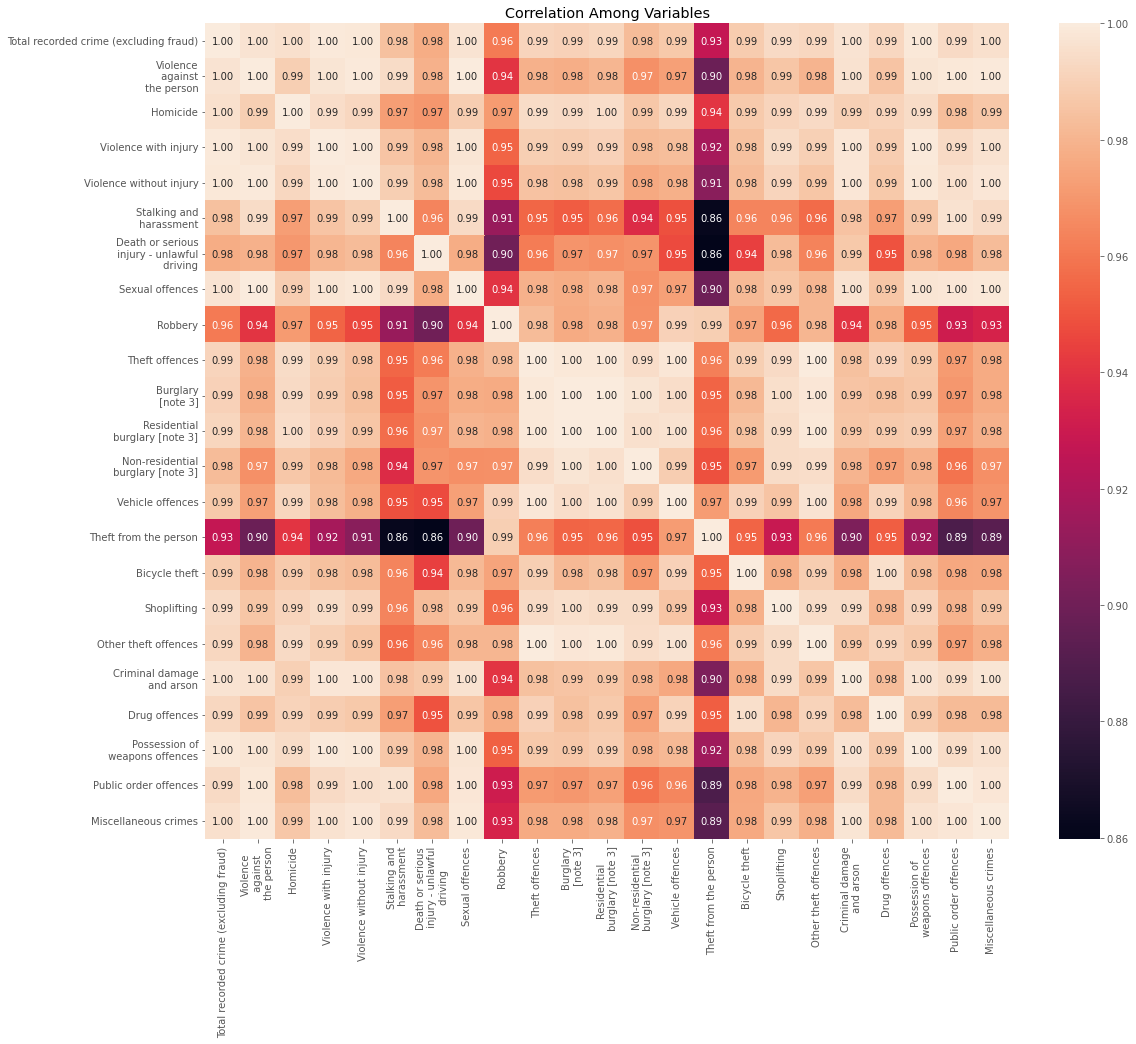

In [ ]:
# computing correlation for variables and visualizing it using seaborn heatmap
corr = df.corr()

plt.figure(figsize=(18,15))
sns.heatmap(corr,annot=True,fmt=".2f")
plt.title("Correlation Among Variables")
plt.show()

### A correlation coefficient is a number between -1 and 1 that tells you the strength and direction of a relationship between variables. If correlation of two variables is +1 than they are strongly correlated and have the same direction which means if one is increased the other one also tends to increase and vice verse

In [ ]:
# computing covariance
covar = df.cov()

covar

,Total recorded crime (excluding fraud),Violence\n against\n the person,Homicide,Violence with injury,Violence without injury,Stalking and\n harassment,Death or serious\n injury - unlawful\n driving,Sexual offences,Robbery,Theft offences,Burglary\n [note 3],Residential\n burglary [note 3],Non-residential\n burglary [note 3],Vehicle offences,Theft from the person,Bicycle theft,Shoplifting,Other theft offences,Criminal damage\n and arson,Drug offences,Possession of\n weapons offences,Public order offences,Miscellaneous crimes
Total recorded crime (excluding fraud),7.795746e+11,2.848367e+11,1.058974e+08,7.933966e+10,1.125635e+11,9.270399e+10,1.235964e+08,2.487586e+10,1.178520e+10,2.459192e+11,4.942470e+10,3.559875e+10,1.382595e+10,6.251910e+10,1.225795e+10,1.275499e+10,4.398340e+10,6.497907e+10,8.003588e+10,3.130838e+10,7.253540e+09,7.630974e+10,1.725009e+10
Violence\n against\n the person,2.848367e+11,1.046989e+11,3.855267e+07,2.902740e+10,4.126896e+10,3.431861e+10,4.536623e+07,9.141817e+09,4.227630e+09,8.896267e+10,1.788215e+10,1.289151e+10,4.990640e+09,2.258166e+10,4.352333e+09,4.633888e+09,1.599352e+10,2.351912e+10,2.931588e+10,1.139123e+10,2.655891e+09,2.810055e+10,6.342104e+09
Homicide,1.058974e+08,3.855267e+07,1.450638e+04,1.077216e+07,1.526027e+07,1.248900e+07,1.673944e+04,3.366040e+06,1.625448e+06,3.363363e+07,6.763516e+06,4.869810e+06,1.893706e+06,8.570529e+06,1.695916e+06,1.738635e+06,5.987787e+06,8.877247e+06,1.083851e+07,4.263144e+06,9.850701e+05,1.030178e+07,2.331137e+06
Violence with injury,7.933966e+10,2.902740e+10,1.077216e+07,8.086093e+09,1.146883e+10,9.449076e+09,1.263117e+07,2.535071e+09,1.192044e+09,2.498162e+10,5.025635e+09,3.618390e+09,1.407245e+09,6.343489e+09,1.235409e+09,1.293674e+09,4.481628e+09,6.601784e+09,8.158694e+09,3.176164e+09,7.390273e+08,7.771925e+09,1.757714e+09
Violence without injury,1.125635e+11,4.126896e+10,1.526027e+07,1.146883e+10,1.629855e+10,1.346835e+10,1.797133e+07,3.603828e+09,1.679249e+09,3.531385e+10,7.102255e+09,5.115790e+09,1.986466e+09,8.962323e+09,1.736274e+09,1.833577e+09,6.345219e+09,9.334201e+09,1.158518e+10,4.501270e+09,1.049119e+09,1.106186e+10,2.500207e+09
Stalking and\n harassment,9.270399e+10,3.431861e+10,1.248900e+07,9.449076e+09,1.346835e+10,1.137397e+10,1.472647e+07,2.995595e+09,1.352920e+09,2.859488e+10,5.739652e+09,4.146829e+09,1.592823e+09,7.257545e+09,1.377111e+09,1.502921e+09,5.153630e+09,7.564021e+09,9.548313e+09,3.704671e+09,8.656044e+08,9.244304e+09,2.079090e+09
Death or serious\n injury - unlawful\n driving,1.235964e+08,4.536623e+07,1.673944e+04,1.263117e+07,1.797133e+07,1.472647e+07,2.052199e+04,3.957440e+06,1.791767e+06,3.869068e+07,7.844933e+06,5.632878e+06,2.212055e+06,9.733131e+06,1.844035e+06,1.976640e+06,7.058142e+06,1.023380e+07,1.285528e+07,4.858112e+06,1.155153e+06,1.215942e+07,2.762327e+06
Sexual offences,2.487586e+10,9.141817e+09,3.366040e+06,2.535071e+09,3.603828e+09,2.995595e+09,3.957440e+06,7.986600e+08,3.692129e+08,7.771251e+09,1.561130e+09,1.125360e+09,4.357700e+08,1.972730e+09,3.805054e+08,4.054806e+08,1.396834e+09,2.054570e+09,2.560303e+09,9.954824e+08,2.319252e+08,2.453506e+09,5.537077e+08
Robbery,1.178520e+10,4.227630e+09,1.625448e+06,1.192044e+09,1.679249e+09,1.352920e+09,1.791767e+06,3.692129e+08,1.930457e+08,3.834310e+09,7.668917e+08,5.525873e+08,2.143044e+08,9.874605e+08,2.057710e+08,1.978728e+08,6.659212e+08,1.010393e+09,1.187698e+09,4.850056e+08,1.089366e+08,1.124724e+09,2.546332e+08
Theft offences,2.459192e+11,8.896267e+10,3.363363e+07,2.498162e+10,3.531385e+10,2.859488e+10,3.869068e+07,7.771251e+09,3.834310e+09,7.888336e+10,1.585170e+10,1.140017e+10,4.451537e+09,2.011277e+10,4.047495e+09,4.060195e+09,1.398967e+10,2.082153e+10,2.513040e+10,9.939110e+09,2.280894e+09,2.373433e+10,5.382892e+09


### Covariance indicates the relationship of two variables whenever one variable changes. If an increase in one variable results in an increase in the other variable, both variables are said to have a positive covariance and vice verse

# Data Preparation For Machine Learning Models
- We are going to develop following models:
- Linear Regression Model
- Clustering

In [ ]:
# checking the dataset again
df.head()

,Area Code,Area Name,Total recorded crime (excluding fraud),Violence\n against\n the person,Homicide,Violence with injury,Violence without injury,Stalking and\n harassment,Death or serious\n injury - unlawful\n driving,Sexual offences,Robbery,Theft offences,Burglary\n [note 3],Residential\n burglary [note 3],Non-residential\n burglary [note 3],Vehicle offences,Theft from the person,Bicycle theft,Shoplifting,Other theft offences,Criminal damage\n and arson,Drug offences,Possession of\n weapons offences,Public order offences,Miscellaneous crimes
0,K04000001,ENGLAND AND WALES [note 4],4856063,1885618,627,494136,716521,673605,729,164763,62803,1358226,265508,195497,70011,344487,59421,79160,247068,362582,502802,198140,45630,524572,113509
1,E92000001,ENGLAND,4573648,1777131,599,467351,677995,630491,695,155727,60966,1295455,254787,187791,66996,333806,55883,74049,234242,342688,466407,183352,43264,483935,107411
2,E12000001,North East,254730,99138,19,24105,33985,40986,43,8450,1424,61172,12200,9085,3115,11075,1231,2568,15922,18176,36859,7336,1961,30812,7578
3,E23000013,Cleveland,65461,25360,7,5579,9339,10420,15,2125,568,16149,3772,2930,842,2750,332,506,4337,4452,9210,2374,590,7131,1954
4,E23000008,Durham,57363,25390,4,5013,8185,12177,11,1873,175,12302,2595,1823,772,2102,195,363,3473,3574,8602,1440,279,5602,1700


In [ ]:
# checking length of area name and code column
print(len(df["Area Code"].unique()))
print(len(df["Area Name"].unique()))

56
61


### The two columns area code and area name have unique values nearly equal to half of the dataset rows, if we use them and encode them using encoders than it will result in an explosion of features to use for Linear Regression model making the model complex, So I will drop these two features from the dataset used for machine learning

In [ ]:
# Splitting the data into features and target variable
X = df.copy()
X.drop(["Area Code","Area Name","Drug offences"],axis=1,inplace=True)
y = df[["Drug offences"]]

In [ ]:
# splitting data into 80% training and 20% testing set
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=21)

# Linear Regression
- Linear regression is a statistical method used to model the relationship between a dependent variable and one or more independent variables. It is a linear approach to modeling the relationship between a scalar response (or dependent variable) and one or more explanatory variables (or independent variables). The goal of linear regression is to find the best-fitting straight line through the data points.

- The equation for a simple linear regression model is:
y = b0 + b1*x **bold text**

- where y is the dependent variable, x is the independent variable, b0 is the y-intercept, and b1 is the coefficient (slope) of the independent variable.

# Models I used for Regression are:
- Linear Regression
- Random Forest Regressor
- Ridge Regressor
- Lasso Regressor

- Following are the metrics I used to evaluate the regression models.

- RMSE (Root Mean Squared Error) is the standard deviation of the residuals. It measures the average distance that the data points deviate from the regression line. It is calculated as the square root of the mean of the squared residuals. A lower RMSE value indicates a better fit.

- R2 score (Coefficient of Determination) is a measure of how well the regression line approximates the real data points. It ranges from 0 to 1, with 1 indicating a perfect fit. A higher R2 score indicates a better fit.

- MAE (Mean Absolute Error) is the average of the absolute values of the residuals. It measures the average magnitude of the errors in the predictions. A lower MAE value indicates a better fit

In [ ]:
# initiating all models
linreg = LinearRegression()
rfr = RandomForestRegressor()
ridge = Ridge()
lasso = Lasso()

# storing the models in a list
models = [linreg,rfr,ridge,lasso]

# stroing the models name in a list
model_names = ["Linear Regression","Random Forest Regressor","Ridge Regression","Lasso Regression"]

# applying a for loop which performs 5 fold cross validation using training set to determine whether the models overfit or not
for model,name in zip(models,model_names):

  # performing cross validation of 5 folds on training set
  cv_score = cross_val_score(model,X_train,y_train,cv=5,scoring="neg_root_mean_squared_error")
  print("cross validation RMSE of {} model are {}".format(name,-1 * cv_score))
  print("-" * 100)

cross validation RMSE of Linear Regression model are [3.92511834e-10 8.99161874e-11 1.24216198e-09 2.49352993e-10
 1.86088274e-10]
----------------------------------------------------------------------------------------------------
cross validation RMSE of Random Forest Regressor model are [2737.50263886 1702.75975753 6580.06764396 5805.86798976 3681.39741452]
----------------------------------------------------------------------------------------------------
cross validation RMSE of Ridge Regression model are [0.00099998 0.00052152 0.00119387 0.00024944 0.00141133]
----------------------------------------------------------------------------------------------------
cross validation RMSE of Lasso Regression model are [1749.96943442 1995.5723837  2565.95559257 2912.98336232 1745.42233321]
----------------------------------------------------------------------------------------------------


### I have performed cross-validation to check for the overfitting of all the 4 models and it seems that Random Forest regressor is overfitting as it is evident from the big difference in RMSE of all the folds, apart from Random Forest Regressor, Lasso Regression also seems to overfit but not as badly as Random Forest Regressor

In [ ]:
# initiating the model
# fitting the model on training data
# getting prediction on the testing data
# computing RMSE
# computing R2 score
# computing MAE

# initiating the model
linreg = LinearRegression()

# fitting the model on training data
linreg.fit(X_train,y_train)

# getting prediction on the testing data
y_pred_linreg = linreg.predict(X_test)

# computing RMSE
rmse_lr = np.sqrt(metrics.mean_squared_error(y_test,y_pred_linreg))

# computing R2 score
coef_deter_lr = metrics.r2_score(y_test,y_pred_linreg)

# computing MAE
mae_lr = metrics.mean_absolute_error(y_test,y_pred_linreg)

print("RMSE of Linear Regression on testing set is {}".format(rmse_lr))
print("-"*100)
print("R2 score of Linear Regression on testing set is {}".format(coef_deter_lr))
print("-"*100)
print("MAE of Linear Regression on testing set is {}".format(mae_lr))
print("-"*100)

RMSE of Linear Regression on testing set is 9.399778539703397e-11
----------------------------------------------------------------------------------------------------
R2 score of Linear Regression on testing set is 1.0
----------------------------------------------------------------------------------------------------
MAE of Linear Regression on testing set is 6.983337579699962e-11
----------------------------------------------------------------------------------------------------


In [ ]:
# initiating the model
rfr = RandomForestRegressor()

# fitting the model on training data
rfr.fit(X_train,y_train)

# getting prediction on the testing data
y_pred_rfr = rfr.predict(X_test)

# computing RMSE
rmse_rfr = np.sqrt(metrics.mean_squared_error(y_test,y_pred_rfr))

# computing R2 score
coef_deter_rfr = metrics.r2_score(y_test,y_pred_rfr)

# computing MAE
mae_rfr = metrics.mean_absolute_error(y_test,y_pred_rfr)

print("RMSE of Random Forest Regressor on testing set is {}".format(rmse_rfr))
print("-"*100)
print("R2 score of Random Forest Regressor on testing set is {}".format(coef_deter_rfr))
print("-"*100)
print("MAE of Random Forest Regressor on testing set is {}".format(mae_rfr))
print("-"*100)

RMSE of Random Forest Regressor on testing set is 2492.3767450376254
----------------------------------------------------------------------------------------------------
R2 score of Random Forest Regressor on testing set is 0.9382715991665135
----------------------------------------------------------------------------------------------------
MAE of Random Forest Regressor on testing set is 1769.448260869565
----------------------------------------------------------------------------------------------------


In [ ]:
# initiating the model
ridge = Ridge()

# fitting the model on training data
ridge.fit(X_train,y_train)

# getting prediction on the testing data
y_pred_ridge = ridge.predict(X_test)

# computing RMSE
rmse_ridge = np.sqrt(metrics.mean_squared_error(y_test,y_pred_ridge))

# computing R2 score
coef_deter_ridge = metrics.r2_score(y_test,y_pred_ridge)

# computing MAE
mae_ridge = metrics.mean_absolute_error(y_test,y_pred_ridge)

print("RMSE of Ridge Regression on testing set is {}".format(rmse_ridge))
print("-"*100)
print("R2 score of Ridge Regression on testing set is {}".format(coef_deter_ridge))
print("-"*100)
print("MAE of Ridge Regression on testing set is {}".format(mae_ridge))
print("-"*100)

RMSE of Ridge Regression on testing set is 0.0006988214948661956
----------------------------------------------------------------------------------------------------
R2 score of Ridge Regression on testing set is 0.9999999999999951
----------------------------------------------------------------------------------------------------
MAE of Ridge Regression on testing set is 0.0005397216405665107
----------------------------------------------------------------------------------------------------


In [ ]:
# initiating the model
lasso = Lasso()

# fitting the model on training data
lasso.fit(X_train,y_train)

# getting prediction on the testing data
y_pred_lasso = lasso.predict(X_test)

# computing RMSE
rmse_lasso = np.sqrt(metrics.mean_squared_error(y_test,y_pred_lasso))

# computing R2 score
coef_deter_lasso = metrics.r2_score(y_test,y_pred_lasso)

# computing MAE
mae_lasso = metrics.mean_absolute_error(y_test,y_pred_lasso)

print("RMSE of Lasso Regression on testing set is {}".format(rmse_lasso))
print("-"*100)
print("R2 score of Lasso Regression on testing set is {}".format(coef_deter_lasso))
print("-"*100)
print("MAE of Lasso Regression on testing set is {}".format(mae_lasso))
print("-"*100)

RMSE of Lasso Regression on testing set is 2345.147066718677
----------------------------------------------------------------------------------------------------
R2 score of Lasso Regression on testing set is 0.9453490379911857
----------------------------------------------------------------------------------------------------
MAE of Lasso Regression on testing set is 1526.9977953467646
----------------------------------------------------------------------------------------------------


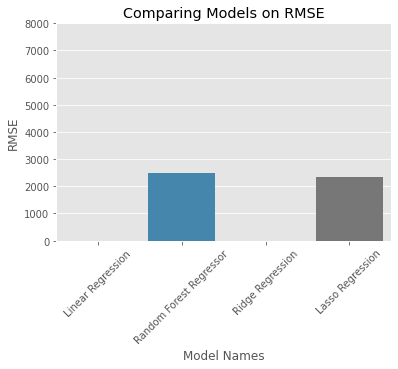

In [ ]:
# comparing all the models performance on the base of RMSE
models_mse = [rmse_lr,rmse_rfr,rmse_ridge,rmse_lasso]

# making a barplot to compare models performance visually on the base RMSE
sns.barplot(model_names,models_mse)
plt.title("Comparing Models on RMSE")
plt.xlabel("Model Names")
plt.ylabel("RMSE")
plt.ylim([rmse_lr,8000])
plt.xticks(rotation=45)
plt.show()

### Linear regression and ridge regression performed the best among all the 4 models. I have compared models on the base of RMSE. I would prefer to use linear regression model becaue not only the RMSE of linear regression is low but it also have r2 score or the coeficient of deterination equals 1, which means that the variability in the dependent variable is very well explained by the independet variables

# Resources to learn Data Science

# Mathematics
- [Staistics_and_probability](https://www.khanacademy.org/math/statistics-probability)
- [Linear_algebra](https://www.youtube.com/watch?v=Qc19jQWHdL0&list=PLRDl2inPrWQW1QSWhBU0ki-jq_uElkh2a)
- [Calculus](https://www.youtube.com/watch?v=en6cnMEviSU&list=PLRDl2inPrWQVu2OvnTvtkRpJ-wz-URMJx)

# Python
- [Datacamp_python_datascience_specialization](https://app.datacamp.com/learn/career-tracks/data-scientist-with-python)

# Some youtube channels
- Codebasics
- Codewithharry
- 3BlueOneBrown
- DataProfessor
- PythonProgrammer

# To learn SQL, R, Tableau

- Google Data Analytics Professional Certificate from Coursera
- Datacamp courses of SQL and Tableau
# Books
- Think Stats Exploratory Data Analysis (Oreilly)
- Hands on Machine Learning With Sciki-learn, keras and tensorflow (Oreilly)
- Deep larning with python
- Practical Statistics for Data Science (Oreilly)
